# Titanic: Machine Learning from Disaster

Predicción de supervivencia de los pasajeros del RMS Titanic a partir del
[dataset de Kaggle](https://www.kaggle.com/competitions/titanic).

- **Tarea:** clasificación binaria (`Survived` = 0/1)
- **Métrica:** accuracy
- **Modelo:** red neuronal densa (Keras / TensorFlow)
- **Resultado:** accuracy de validación 0.8212 · public LB 0.76794


In [1]:
# Dependencias del entorno (en local: pip install -r requirements.txt)
!pip install -q kagglehub tensorflow


## 1. Entorno y credenciales

Instala las dependencias y define el token de la API de Kaggle.

El token **no** se escribe en el notebook: se lee de una variable de entorno o
de los *Secrets* de Colab (`KAGGLE_API_TOKEN`). Consíguelo en
[kaggle.com/settings](https://www.kaggle.com/settings) → *API* → *Create New Token*.


In [3]:
import os

# Token de Kaggle: nunca hardcodear.
#   Colab  -> guardarlo en Secrets con el nombre KAGGLE_API_TOKEN
#   Local  -> export KAGGLE_API_TOKEN=... antes de abrir el notebook
try:
    from google.colab import userdata
    os.environ.setdefault("KAGGLE_API_TOKEN", userdata.get("KAGGLE_API_TOKEN"))
except Exception:
    pass

assert os.environ.get("KAGGLE_API_TOKEN"), (
    "Define KAGGLE_API_TOKEN (Colab Secrets o variable de entorno)"
)


## 2. Descarga del dataset

`kagglehub` descarga la competición y devuelve la ruta local que contiene
`train.csv` y `test.csv`.


In [4]:
import kagglehub
# Descarga la competición y devuelve la carpeta con train.csv y test.csv
path = kagglehub.competition_download('titanic')
print("Path:", path)

100%|██████████| 34.1k/34.1k [00:00<00:00, 31.0MB/s]

Extracting files...
Path: /root/.cache/kagglehub/competitions/titanic


## 3. Librerías y carga de datos

- 891 filas de entrenamiento (con la etiqueta `Survived`)
- 418 filas de test (sin etiqueta, para el submission)


In [5]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report

# Carpeta local con train.csv y test.csv
DATA_DIR = path
train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test  = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
print(train.shape, test.shape)
train.head()

(891, 12) (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 4. Ingeniería de variables

| Variable | Cálculo | Motivación |
|---|---|---|
| `Title` | extraído de `Name` | el tratamiento (Mr, Mrs, Miss…) aproxima edad, sexo y clase |
| `FamilySize` | `SibSp + Parch + 1` | el tamaño de la familia afecta la supervivencia |
| `IsAlone` | `FamilySize == 1` | viajar solo es un caso distinto |
| `Cabin` | primera letra (o `U` si falta) | la cubierta aproxima la ubicación en el barco |

Además se aplica `log1p` a `Fare` (distribución muy sesgada) y las variables
categóricas se codifican con one-hot.


In [6]:
def preprocess(df):
    df = df.copy()
    # Título del nombre
    df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")
    df["Title"] = df["Title"].replace(
        ["Lady","Countess","Capt","Col","Don","Dr","Major","Rev",
         "Sir","Jonkheer","Dona"], "Rare")
    df["Title"] = df["Title"].replace({"Mlle":"Miss","Ms":"Miss","Mme":"Mrs"})
    # Familia
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    df["IsAlone"]    = (df["FamilySize"] == 1).astype(int)
    # Cabina → letra inicial
    df["Cabin"] = df["Cabin"].fillna("U").str[0]
    # Fare con log (maneja NaNs en test)
    df["Fare"] = df["Fare"].fillna(df["Fare"].median())
    df["FareLog"] = np.log1p(df["Fare"])
    return df

train_p = preprocess(train)
test_p  = preprocess(test)

features = ["Pclass","Sex","Age","SibSp","Parch","FareLog",
            "Embarked","Title","FamilySize","IsAlone","Cabin"]

X = train_p[features].copy()
y = train_p["Survived"].values
X_test = test_p[features].copy()

cat_cols = ["Sex","Embarked","Title","Cabin"]
for c in cat_cols:
    X[c]      = X[c].astype(str)
    X_test[c] = X_test[c].astype(str)

X      = pd.get_dummies(X, columns=cat_cols)
X_test = pd.get_dummies(X_test, columns=cat_cols)
X_test = X_test.reindex(columns=X.columns, fill_value=0)  # alinear

## 5. Imputación y escalado

- `SimpleImputer(median)` rellena los nulos de `Age` y demás numéricos
- `StandardScaler` lleva todas las variables a la misma escala
- Las columnas de test se alinean con las de train (`reindex`) → 28 features


In [7]:
num_cols = ["Age","SibSp","Parch","FareLog","FamilySize","IsAlone","Pclass"]

# Rellenar nulos con la mediana (robusta a valores extremos)
imp = SimpleImputer(strategy="median")
X[num_cols]      = imp.fit_transform(X[num_cols])
X_test[num_cols] = imp.transform(X_test[num_cols])

# Estandarizar: media 0 y desviación 1
scaler = StandardScaler()
X[num_cols]      = scaler.fit_transform(X[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

X      = X.values.astype(np.float32)
X_test = X_test.values.astype(np.float32)
print("X:", X.shape, " X_test:", X_test.shape)

X: (891, 28)  X_test: (418, 28)


## 6. Modelo: red neuronal densa

Arquitectura `64 → 32 → 16 → 1` (sigmoide) con dropout (0.4 / 0.3 / 0.2) para
reducir el sobreajuste en un dataset tan pequeño.

Entrenamiento: Adam(1e-3), binary crossentropy y `EarlyStopping` sobre
`val_loss` (patience 20, restaura los mejores pesos).


In [8]:
tf.random.set_seed(42)

def build_model(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(16, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model

# Split 80/20 estratificado: conserva la proporción de supervivientes
X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

model = build_model(X.shape[1])
model.summary()

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=20,
    restore_best_weights=True, verbose=1)

history = model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=300, batch_size=32,
    callbacks=[early_stop], verbose=0)
print("Épocas entrenadas:", len(history.history["loss"]))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,481 (17.50 KB)

 Trainable params: 4,481 (17.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 63: early stopping
Restoring model weights from the end of the best epoch: 43.
Épocas entrenadas: 63


## 7. Evaluación y submission

- Accuracy y `classification_report` sobre el 20 % de validación
- Predicción de test con umbral 0.5 → `submission.csv` (418 filas)


In [11]:
y_val_pred = (model.predict(X_val, verbose=0) > 0.5).astype(int).ravel()
print("Val accuracy:", accuracy_score(y_val, y_val_pred))
print(classification_report(y_val, y_val_pred, target_names=["No","Sí"]))

# Umbral 0.5: probabilidad > 0.5 -> sobrevive
test_pred = (model.predict(X_test, verbose=0) > 0.5).astype(int).ravel()

submission = pd.DataFrame({
    "PassengerId": test_p["PassengerId"].values,
    "Survived":    test_pred,
})
submission.to_csv("submission.csv", index=False)
print(submission.head())
print("Filas:", len(submission))  # debe ser 418

Val accuracy: 0.8212290502793296
              precision    recall  f1-score   support

          No       0.81      0.92      0.86       110
          Sí       0.84      0.67      0.74        69

    accuracy                           0.82       179
   macro avg       0.83      0.79      0.80       179
weighted avg       0.82      0.82      0.82       179

   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         1
Filas: 418


## 8. Descarga del fichero (Colab)

En Colab descarga `submission.csv` al equipo. Fuera de Colab el fichero ya queda
en el directorio de trabajo.


In [12]:
# En Colab descarga el fichero; fuera de Colab ya está en el directorio
try:
    from google.colab import files
    files.download("submission.csv")
except Exception:
    print("submission.csv generado en el directorio del notebook")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Curvas de entrenamiento

Loss y accuracy por época para train y validación. Sirven para comprobar si el
modelo sobreajusta o si el early stopping cortó demasiado pronto.


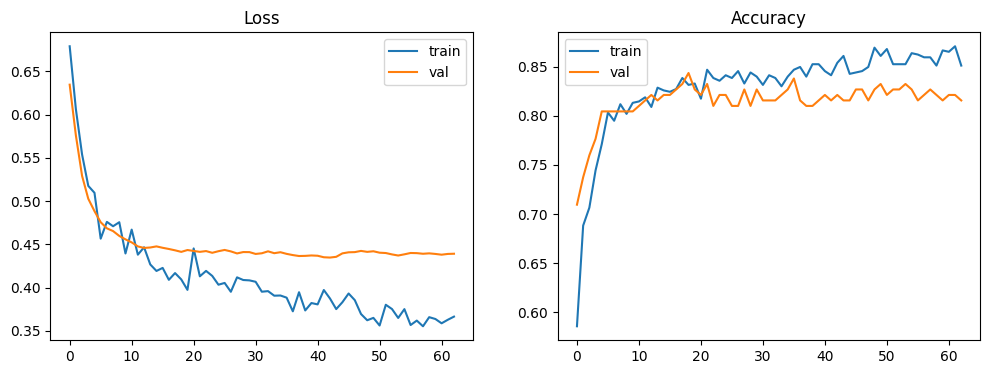

In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["loss"],     label="train")
ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history.history["accuracy"],     label="train")
ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()